# 08 — v20b vs ViT-e (subset)

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe).
Même split : **924 train / 653 val**, seed 42.

**Pilote : `RUNS` uniquement.** Commenter une ligne retire un checkpoint.
Pas d'overlays, pas de table `LABELS`.

Références :
- **v20b** : CNN subset (val ~0,839 / gold ~0,885). Deltas = run − v20b.
- **ViT-e** : graphe CAM+LSTM, lr uniforme 3e-5.

Le ViT n'est pas un successeur **macro**. Il sert en **spécialiste d'ensemble** :
têtes où il bat v20b de plus de 0,01 (Contusion / Effusion / Baker / ACL chez k).
Δ macro **&lt; 0,01** = bruit. Gold n=58, jamais pour le checkpoint.

Relancer **load → graphes** pendant un train : `history.json` s'écrit chaque epoch.


In [10]:
from __future__ import annotations

import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Seul levier du notebook : commenter une ligne pour exclure un run.
RUNS = [
    "subset_v20b_crop130_frac025",            # CNN subset (REF)
    "subset_v20e_crop130_det_frac025",        # pooling par finding, det seed 42
    "subset_vit_dinov3_e_crop130_frac025",    # ViT-e baseline
    "subset_vit_k_llrd08_det_frac025",
    "subset_vit_k_dp01_det_frac025",
    "subset_vit_k_ls05_det_frac025",          # k det + label_smoothing 0.05
]

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]
# Fallback si aucun ViT ne bat v20b de > 0.01 (debut de train).
DEFAULT_SPECIALIST = ["Contusion", "Effusion", "Baker's", "ACL"]
NOISE = 0.01


def run_label(name: str) -> str:
    s = name[7:] if name.startswith("subset_") else name
    return s.replace("_crop130", "").replace("_frac025", "")


print("ROOT", ROOT)
print("RUNS", RUNS)


ROOT c:\Users\sulta\Documents\RSNA-comp
RUNS ['subset_v20b_crop130_frac025', 'subset_v20e_crop130_det_frac025', 'subset_vit_dinov3_e_crop130_frac025', 'subset_vit_k_llrd08_det_frac025', 'subset_vit_k_dp01_det_frac025', 'subset_vit_k_ls05_det_frac025']


In [11]:
def load_run(name: str) -> dict | None:
    d = CKPT / name
    hist_p = d / "history.json"
    if not hist_p.exists():
        print(f"  skip {run_label(name)} : pas de history.json")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {run_label(name)} : history.json vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists():
        gold = json.loads(gp.read_text(encoding="utf-8"))
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    gold_best = None
    if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")):
        gold_best = float(best_row["gold_macro_auc"])
    return {
        "name": name,
        "label": run_label(name),
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "done": gp.exists(),
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": gold_best,
        "last_epoch": int(hist["epoch"].max()),
        "n_epochs": int(len(hist)),
    }


def line_kw(r: dict) -> dict:
    return dict(marker="o", label=r["label"])


runs = []
print("runs demandes :", [run_label(n) for n in RUNS])
for name in RUNS:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    etat = "termine" if rec["done"] else f"{rec['n_epochs']} epochs"
    print(
        f"  {rec['label']}: {etat} | best val {rec['best_val']:.4f} "
        f"@ ep {rec['best_epoch']} | {gold_txt} | n_train {len(rec['uids']) or '?'}"
    )

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")

REF = next((n for n in RUNS if "v20b" in n), runs[0]["name"])
VIT_E = next((n for n in RUNS if "dinov3_e" in n), None)
print("REF (CNN)", run_label(REF))
if VIT_E:
    print("ViT-e", run_label(VIT_E))


runs demandes : ['v20b', 'v20e_det', 'vit_dinov3_e', 'vit_k_llrd08_det', 'vit_k_dp01_det', 'vit_k_ls05_det']
  v20b: 10 epochs | best val 0.8389 @ ep 10 | gold 0.885 | n_train 924
  v20e_det: 4 epochs | best val 0.7646 @ ep 4 | gold 0.775 | n_train 924
  vit_dinov3_e: 7 epochs | best val 0.8075 @ ep 7 | gold 0.814 | n_train 924
  vit_k_llrd08_det: 11 epochs | best val 0.8132 @ ep 10 | gold 0.814 | n_train 924
  vit_k_dp01_det: 8 epochs | best val 0.8021 @ ep 8 | gold 0.810 | n_train 924
  vit_k_ls05_det: 9 epochs | best val 0.8088 @ ep 9 | gold 0.809 | n_train 924
REF (CNN) v20b
ViT-e vit_dinov3_e


## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).


In [12]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["label"],
        "name": r["name"],
        "etat": "termine" if r["done"] else f"{r['n_epochs']} ep",
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.drop(columns=["name"]).round(4))

ref_row = next((row for _, row in summary.iterrows() if row["name"] == REF), None)
if ref_row is not None and len(summary) > 1:
    print("\ndelta vs", run_label(REF), "(best val AUC)")
    for lab, row in summary.iterrows():
        if row["name"] == REF:
            continue
        d = row["best_val_auc"] - ref_row["best_val_auc"]
        print(f"  {lab}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < NOISE else ''}")


,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,
v20b,10 ep,924,10,0.8389,0.8853,0.3359,0.3844,0.8389
v20e_det,4 ep,924,4,0.7646,0.7752,0.4276,0.4323,0.7646
vit_dinov3_e,7 ep,924,7,0.8075,0.8144,0.3777,0.4332,0.8075
vit_k_llrd08_det,11 ep,924,10,0.8132,0.8142,0.2452,0.5134,0.8077
vit_k_dp01_det,8 ep,924,8,0.8021,0.8097,0.3919,0.4689,0.8021
vit_k_ls05_det,9 ep,924,9,0.8088,0.8086,0.3652,0.4643,0.8088



delta vs v20b (best val AUC)
  v20e_det: -0.0743  
  vit_dinov3_e: -0.0314  
  vit_k_llrd08_det: -0.0257  
  vit_k_dp01_det: -0.0368  
  vit_k_ls05_det: -0.0301  


## Courbes (tous les runs superposés)

courbes v20b: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
courbes v20e_det: epochs [1, 2, 3, 4]
courbes vit_dinov3_e: epochs [1, 2, 3, 4, 5, 6, 7]
courbes vit_k_llrd08_det: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
courbes vit_k_dp01_det: epochs [1, 2, 3, 4, 5, 6, 7, 8]
courbes vit_k_ls05_det: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9]


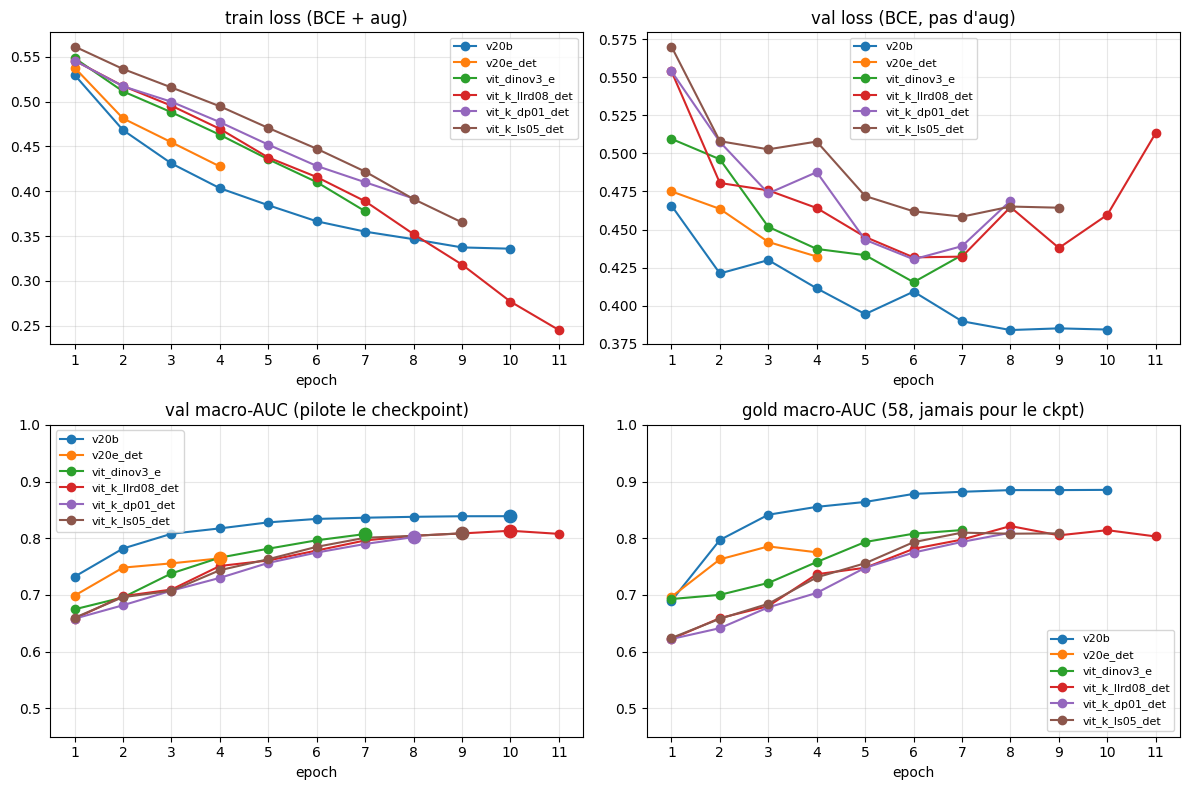

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"].sort_values("epoch")
    kw = line_kw(r)
    print(f"courbes {r['label']}: epochs {list(map(int, h.epoch))}")
    axes[0, 0].plot(h.epoch, h.loss, **kw)
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, **kw)
    axes[1, 0].plot(h.epoch, h.val_macro_auc, **kw)
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, **kw)
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

emax = max(int(r["hist"]["epoch"].max()) for r in runs)
axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()


## AUC par cible à la meilleure epoch

Barres = les 12 findings. En **gras** : le ViT y est **spécialiste** (bat v20b de &gt; 0,01).


specialiste ViT vs v20b (Δ > 0.01) : ['Lateral Meniscus', 'Effusion', 'Contusion']


,subset_v20b_crop130_frac025,subset_v20e_crop130_det_frac025,subset_vit_dinov3_e_crop130_frac025,subset_vit_k_llrd08_det_frac025,subset_vit_k_dp01_det_frac025,subset_vit_k_ls05_det_frac025,d_subset_v20e_crop130_det_frac025,d_subset_vit_dinov3_e_crop130_frac025,d_subset_vit_k_llrd08_det_frac025,d_subset_vit_k_dp01_det_frac025,d_subset_vit_k_ls05_det_frac025
ACL,0.800000,0.729000,0.762000,0.757000,0.762000,0.744000,-0.071000,-0.039000,-0.043000,-0.038000,-0.057000
MCL,0.797000,0.654000,0.732000,0.703000,0.686000,0.702000,-0.144000,-0.065000,-0.095000,-0.111000,-0.095000
Medial Meniscus,0.919000,0.746000,0.804000,0.862000,0.826000,0.848000,-0.173000,-0.115000,-0.057000,-0.093000,-0.071000
Lateral Meniscus,0.825000,0.679000,0.778000,0.849000,0.790000,0.837000,-0.147000,-0.048000,0.023000,-0.036000,0.012000
Medial OA,0.855000,0.834000,0.860000,0.849000,0.835000,0.839000,-0.021000,0.006000,-0.006000,-0.020000,-0.016000
Lateral OA,0.798000,0.764000,0.790000,0.772000,0.763000,0.765000,-0.035000,-0.009000,-0.027000,-0.036000,-0.033000
PF OA,0.813000,0.755000,0.785000,0.753000,0.774000,0.757000,-0.058000,-0.028000,-0.060000,-0.039000,-0.056000
Effusion,0.827000,0.803000,0.861000,0.831000,0.844000,0.826000,-0.025000,0.034000,0.004000,0.017000,-0.001000
Synovitis,0.849000,0.835000,0.854000,0.850000,0.822000,0.842000,-0.013000,0.005000,0.001000,-0.026000,-0.007000
Baker's,0.903000,0.834000,0.822000,0.901000,0.884000,0.905000,-0.069000,-0.081000,-0.002000,-0.019000,0.002000


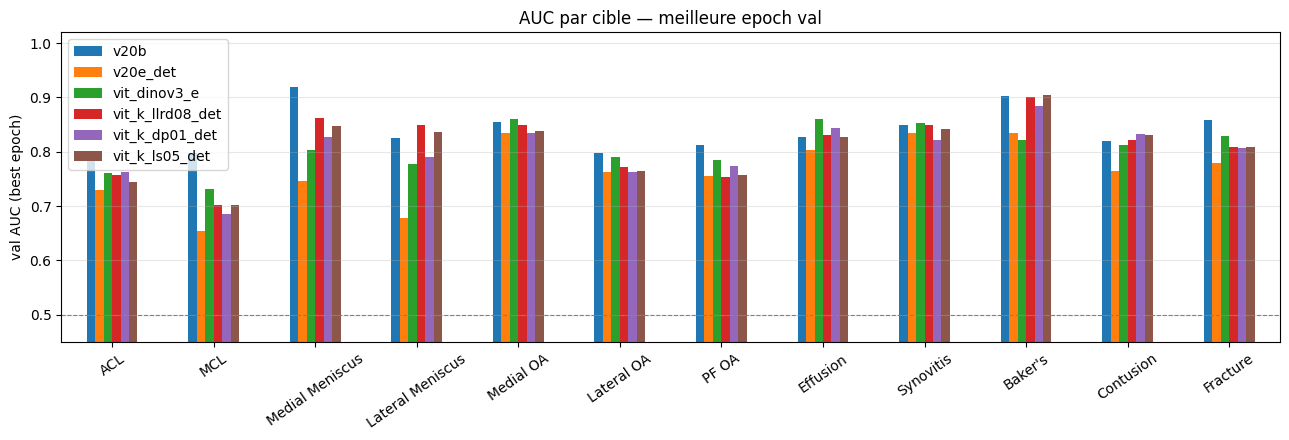

In [14]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

vit_names = [r["name"] for r in runs if r["name"] != REF]
FOCUS = list(DEFAULT_SPECIALIST)
if REF in per_df.columns and vit_names:
    FOCUS = []
    for t in TARGETS:
        dmax = float((per_df.loc[t, vit_names] - per_df.loc[t, REF]).max())
        if dmax > NOISE:
            FOCUS.append(t)
    if not FOCUS:
        FOCUS = list(DEFAULT_SPECIALIST)
        print("aucun specialiste > 0.01 vs v20b (train trop tot ?) → fallback", FOCUS)
    else:
        print("specialiste ViT vs v20b (Δ > 0.01) :", FOCUS)

if REF in per_df.columns:
    for c in [x for x in per_df.columns if x != REF]:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

plot_df = per_df[[r["name"] for r in runs]].rename(
    columns={r["name"]: r["label"] for r in runs}
)
ax = plot_df.plot(kind="bar", figsize=(13, 4.5), rot=35)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Delta par cible vs v20b

Positif = le run bat le CNN. Rouge = spécialiste ViT. Δ &lt; 0,01 = bruit.


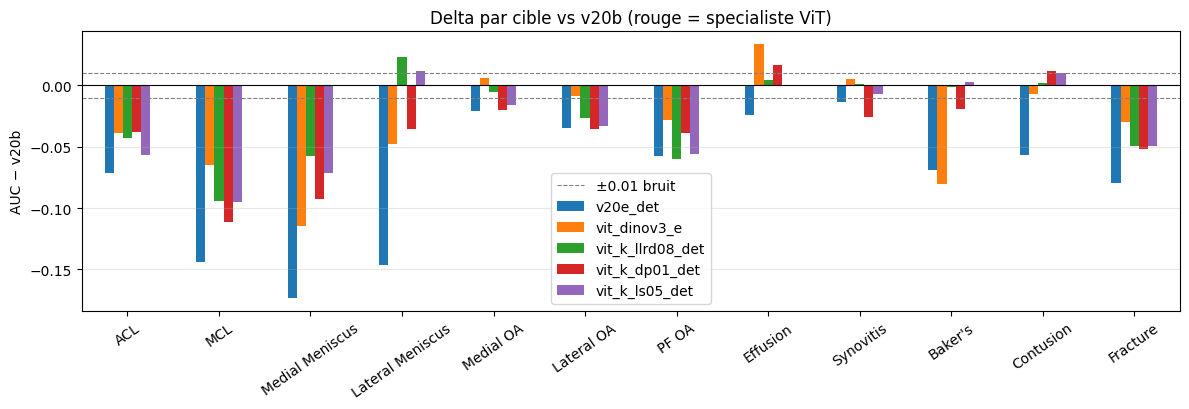

specialiste (val best epoch) :


,subset_v20b_crop130_frac025,subset_v20e_crop130_det_frac025,subset_vit_dinov3_e_crop130_frac025,subset_vit_k_llrd08_det_frac025,subset_vit_k_dp01_det_frac025,subset_vit_k_ls05_det_frac025,d_subset_v20e_crop130_det_frac025,d_subset_vit_dinov3_e_crop130_frac025,d_subset_vit_k_llrd08_det_frac025,d_subset_vit_k_dp01_det_frac025,d_subset_vit_k_ls05_det_frac025
Lateral Meniscus,0.825,0.679,0.778,0.849,0.790,0.837,-0.147,-0.048,0.023,-0.036,0.012
Effusion,0.827,0.803,0.861,0.831,0.844,0.826,-0.025,0.034,0.004,0.017,-0.001
Contusion,0.821,0.764,0.813,0.822,0.832,0.831,-0.057,-0.007,0.002,0.012,0.010


In [15]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut REF={run_label(REF)!r} dans RUNS et charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [run_label(c[2:]) for c in d.columns]
    colors = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {run_label(REF)}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {run_label(REF)}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(NOISE, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-NOISE, color="gray", ls="--", lw=0.8)
    ax.set_title("Delta par cible vs v20b (rouge = specialiste ViT)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("specialiste (val best epoch) :")
    display(per_df.loc[FOCUS].round(3))


## Courbes des têtes spécialiste (toutes les epochs)

Là où un ViT de `RUNS` bat v20b. C'est le signal d'ensemble, pas la macro.


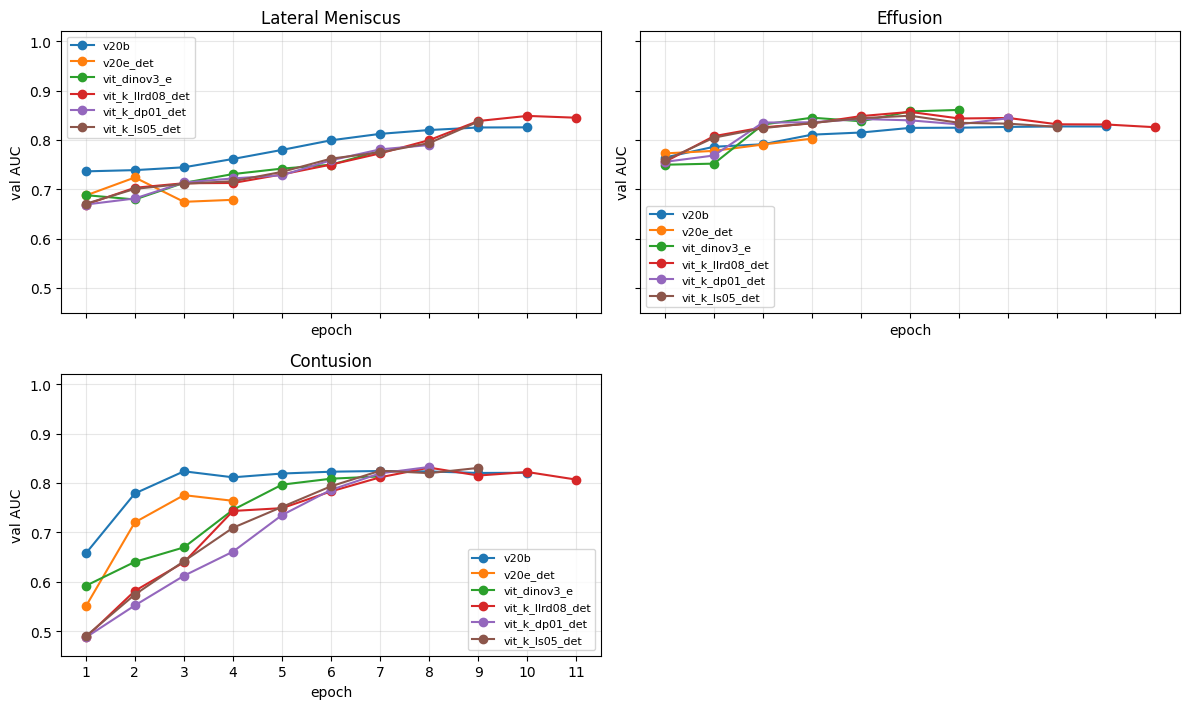

In [16]:
tgts = [t for t in FOCUS if any(f"auc_{t}" in r["hist"].columns for r in runs)]
n = max(len(tgts), 1)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows), sharex=True, sharey=True)
if nrows == 1 and ncols == 1:
    axes = [axes]
elif nrows == 1 or ncols == 1:
    axes = list(axes)
else:
    axes = [ax for row in axes for ax in row]
emax = max(int(r["hist"]["epoch"].max()) for r in runs)
for ax, tgt in zip(axes, tgts):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"].sort_values("epoch")
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], **line_kw(r))
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
for ax in axes[len(tgts):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.


In [17]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer")
else:
    names = list(uid_sets)
    ref_n = names[0]
    sref = uid_sets[ref_n]
    ok = True
    print(f"ref UIDs : {run_label(ref_n)} ({len(sref)})")
    for n in names[1:]:
        s = uid_sets[n]
        print(
            f"  {run_label(n)}: {len(s)} | "
            f"inter {len(sref & s)} | seulement ref {len(sref - s)} | "
            f"seulement run {len(s - sref)}"
        )
        if s != sref:
            ok = False
    if ok:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")


ref UIDs : v20b (924)
  v20e_det: 924 | inter 924 | seulement ref 0 | seulement run 0
  vit_dinov3_e: 924 | inter 924 | seulement ref 0 | seulement run 0
  vit_k_llrd08_det: 924 | inter 924 | seulement ref 0 | seulement run 0
  vit_k_dp01_det: 924 | inter 924 | seulement ref 0 | seulement run 0
  vit_k_ls05_det: 924 | inter 924 | seulement ref 0 | seulement run 0
OK : exactement les memes etudes train


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utiliser la courbe `gold_macro_auc` ci-dessus.


In [18]:
gcols = {}
for r in runs:
    if not r["gold"]:
        print(f"{r['label']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['label']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in list(gdf.columns):
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    plot_g = gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].rename(
        columns={r["name"]: r["label"] for r in runs if r["name"] in gdf.columns}
    )
    plot_g.plot(kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)")
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


v20b: pas encore de gold_sanity.json
v20e_det: pas encore de gold_sanity.json
vit_dinov3_e: pas encore de gold_sanity.json
vit_k_llrd08_det: pas encore de gold_sanity.json
vit_k_dp01_det: pas encore de gold_sanity.json
vit_k_ls05_det: pas encore de gold_sanity.json


## Comment lire

1. **Val macro-AUC** : pilote le checkpoint. Δ &lt; 0,01 → pas de gagnant.
2. **Spécialiste** : têtes en gras / courbes FOCUS, où un ViT &gt; v20b + 0,01.
   C'est le critère d'ensemble (Contusion, Effusion, parfois Baker / ACL), pas la macro.
3. **ViT-e** : parent graphe. **k** : même graphe + LLRD. Un k local déterministe
   qui reste ~0,02 sous le k RunPod n'invalide pas le levier (stack 3070).
4. **Gold** : n=58, bruité. Ne jamais piloter dessus.

Pour rafraîchir : **re-exécuter à partir de Load**. Pour changer l'analyse : **`RUNS`**.
